In [1]:
from pathlib import Path

import numpy as np
import torch
from IPython.display import display
from PIL import Image

FIBONACCI_PATH = Path('./outputs/studio_small_09_fibonacci.npz')
OUTPUT_DIR = Path('./outputs/studio_small_09_cube_from_fibonacci')
FACE_SIZE = 512
NUM_NEIGHBORS = 4
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

FACE_NAMES = ('+X', '-X', '+Y', '-Y', '+Z', '-Z')
FACE_FILES = ('posx.png', 'negx.png', 'posy.png', 'negy.png', 'posz.png', 'negz.png')

In [2]:
def make_face_directions(face_size, face, device=None, dtype=torch.float32):
    """Return unit directions [S, S, 3]; image rows point down, world +Y up."""
    if not isinstance(face_size, int) or face_size < 1:
        raise ValueError('face_size must be a positive integer')
    if face not in FACE_NAMES:
        raise ValueError(f'Unknown face: {face}')

    # Sample at pixel centers in the face coordinate system.
    axis = 2 * (torch.arange(face_size, device=device, dtype=dtype) + 0.5) / face_size - 1
    t, s = torch.meshgrid(axis, axis, indexing='ij')
    one = torch.ones_like(s)

    if face == '+X':
        xyz = torch.stack((one, -t, -s), dim=-1)
    elif face == '-X':
        xyz = torch.stack((-one, -t, s), dim=-1)
    elif face == '+Y':
        xyz = torch.stack((s, one, t), dim=-1)
    elif face == '-Y':
        xyz = torch.stack((s, -one, -t), dim=-1)
    elif face == '+Z':
        xyz = torch.stack((s, -t, one), dim=-1)
    else:  # -Z
        xyz = torch.stack((-s, -t, -one), dim=-1)

    return xyz / xyz.norm(dim=-1, keepdim=True)

In [3]:
def fibonacci_to_cubemap(directions, rgb, face_size, num_neighbors=4):
    """Interpolate directions [N, 3] and RGB [B, N, 3] to [B, 6, 3, S, S]."""
    if directions.ndim != 2 or directions.shape[1] != 3 or directions.shape[0] < 1:
        raise ValueError('Expected nonempty directions with shape [N, 3]')
    num_samples = directions.shape[0]
    if rgb.ndim != 3 or rgb.shape[0] < 1 or rgb.shape[1:] != (num_samples, 3):
        raise ValueError('Expected RGB with shape [B, N, 3] matching the directions')
    if directions.dtype not in (torch.float32, torch.float64) or rgb.dtype != directions.dtype:
        raise TypeError('Directions and RGB must use the same float32 or float64 dtype')
    if directions.device != rgb.device:
        raise ValueError('Directions and RGB must be on the same device')
    if not isinstance(face_size, int) or isinstance(face_size, bool) or face_size < 1:
        raise ValueError('face_size must be a positive integer')
    if not isinstance(num_neighbors, int) or isinstance(num_neighbors, bool) or num_neighbors < 1:
        raise ValueError('num_neighbors must be a positive integer')
    if not torch.isfinite(directions).all() or not torch.isfinite(rgb).all():
        raise ValueError('Directions and RGB must contain finite values')
    norms = directions.norm(dim=-1, keepdim=True)
    if not torch.allclose(norms, torch.ones_like(norms), atol=1e-5, rtol=0):
        raise ValueError('Expected unit directions')
    directions = directions / norms

    queries = torch.stack([
        make_face_directions(face_size, face, device=directions.device, dtype=directions.dtype)
        for face in FACE_NAMES
    ]).reshape(-1, 3)

    # Bound the size of the temporary query-by-sample similarity matrix.
    neighbors = min(num_neighbors, num_samples)
    pixels_per_chunk = max(1, (4 * 1024 * 1024) // num_samples)
    face_pixels = rgb.new_empty(rgb.shape[0], len(queries), 3)
    for start in range(0, len(queries), pixels_per_chunk):
        chunk = queries[start:start + pixels_per_chunk]
        indices = (chunk @ directions.T).topk(neighbors, dim=-1).indices
        offsets = chunk[:, None, :] - directions[indices]
        distance_squared = offsets.square().sum(dim=-1)
        exact = distance_squared == 0
        weights = distance_squared.clamp_min(torch.finfo(directions.dtype).eps ** 2).reciprocal()
        weights = torch.where(exact.any(dim=-1, keepdim=True), exact.to(weights.dtype), weights)
        weights = weights / weights.sum(dim=-1, keepdim=True)
        face_pixels[:, start:start + len(chunk)] = (rgb[:, indices] * weights[..., None]).sum(dim=2)

    return face_pixels.reshape(rgb.shape[0], 6, face_size, face_size, 3).permute(0, 1, 4, 2, 3).contiguous()

In [4]:
with np.load(FIBONACCI_PATH, allow_pickle=False) as samples:
    directions = torch.from_numpy(samples['directions']).to(DEVICE)
    rgb = torch.from_numpy(samples['rgb']).to(DEVICE)

cube = fibonacci_to_cubemap(directions, rgb, FACE_SIZE, NUM_NEIGHBORS)
print('Cubemap:', tuple(cube.shape), 'device:', cube.device)
print('HDR range:', (cube.min().item(), cube.max().item()))

Cubemap: (1, 6, 3, 512, 512) device: cuda:0
HDR range: (0.001057353219948709, 324.3101501464844)


Saved: E:\model\erpProcess\outputs\studio_small_09_cube_from_fibonacci\cubemap.npz


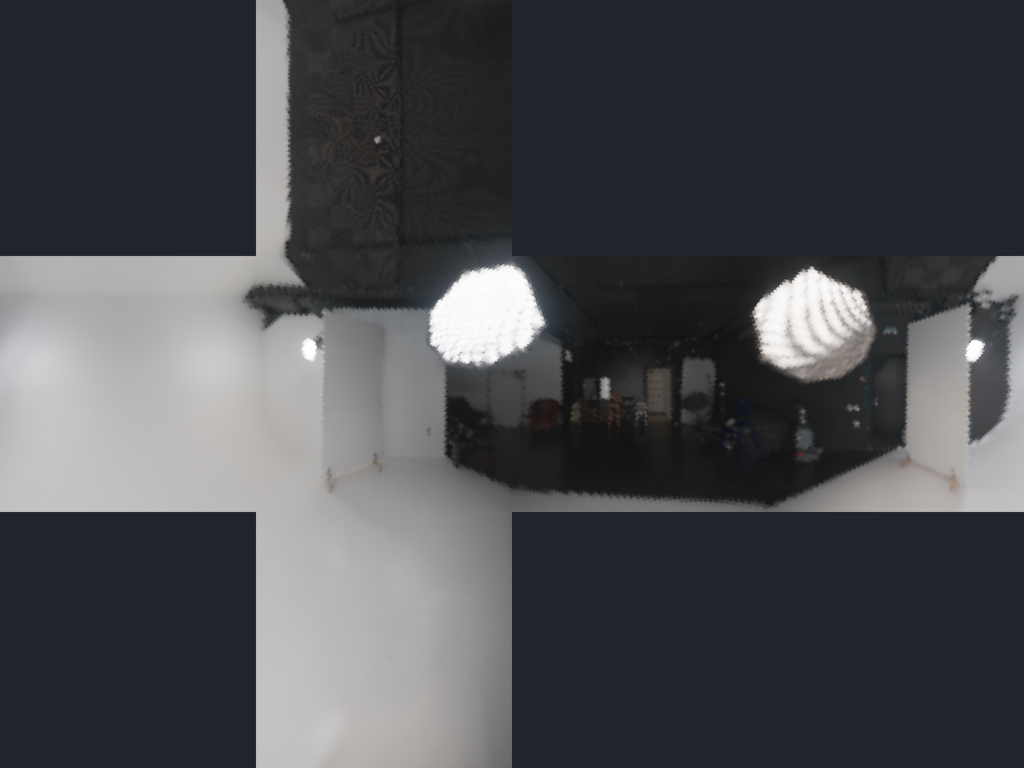

In [5]:
cube_values = cube.detach().cpu().numpy()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cube_path = OUTPUT_DIR / 'cubemap.npz'
np.savez_compressed(cube_path, cubemap=cube_values, num_samples=directions.shape[0])
print('Saved:', cube_path.resolve())

face_rgb = cube_values[0].transpose(0, 2, 3, 1)
face_rgb = np.maximum(face_rgb, 0)
png_pixels = np.rint((face_rgb / (1 + face_rgb)) ** (1 / 2.2) * 255).astype(np.uint8)
placements = {'+Y': (1, 0), '-X': (0, 1), '+Z': (1, 1), '+X': (2, 1), '-Z': (3, 1), '-Y': (1, 2)}
cross = Image.new('RGB', (4 * FACE_SIZE, 3 * FACE_SIZE), '#20242b')
for name, filename, pixels in zip(FACE_NAMES, FACE_FILES, png_pixels):
    image = Image.fromarray(pixels)
    image.save(OUTPUT_DIR / filename)
    col, row = placements[name]
    cross.paste(image, (col * FACE_SIZE, row * FACE_SIZE))
cross.save(OUTPUT_DIR / 'cubemap_cross.png')
cross.thumbnail((1024, 768), Image.Resampling.LANCZOS)
display(cross)